In [1]:

# STEP 1: UPLOAD AND EXTRACT THE KAGGLE ZIP FILE

from google.colab import files
import zipfile
import os
import glob

# Upload archive.zip
print("Bro, select your downloaded archive.zip file")
uploaded = files.upload()

# Find the uploaded ZIP file
zip_files = [name for name in uploaded if name.lower().endswith(".zip")]

if not zip_files:
    raise ValueError("Please upload the downloaded ZIP file.")

zip_path = zip_files[0]
extract_folder = "/content/imd_rainfall_dataset"

# Create folder and extract ZIP
os.makedirs(extract_folder, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_folder)

print("\nZIP file extracted successfully!")

# Display all extracted files
for root, dirs, filenames in os.walk(extract_folder):
    for filename in filenames:
        print(os.path.join(root, filename))

# Automatically locate CSV files
csv_files = glob.glob(
    os.path.join(extract_folder, "**", "*.csv"),
    recursive=True
)

if not csv_files:
    raise ValueError(
        "No CSV found inside the ZIP. Please check the archive contents."
    )

print("\nCSV files found:")
for i, path in enumerate(csv_files, start=1):
    print(i, os.path.basename(path))

# Select the first CSV automatically
dataset_path = csv_files[0]

print("\nSelected dataset:", dataset_path)

# Load and inspect the dataset
import pandas as pd

df = pd.read_csv(dataset_path)

print("\nDataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())


Bro, select your downloaded archive.zip file


Saving archive.zip to archive.zip

ZIP file extracted successfully!
/content/imd_rainfall_dataset/Indian Rainfall Dataset District-wise Daily Measurements.csv

CSV files found:
1 Indian Rainfall Dataset District-wise Daily Measurements.csv

Selected dataset: /content/imd_rainfall_dataset/Indian Rainfall Dataset District-wise Daily Measurements.csv

Dataset loaded successfully!
Shape: (8790, 1)

Column names:
['state;"district";"month";"1st";"2nd";"3rd";"4th";"5th";"6th";"7th";"8th";"9th";"10th";"11th";"12th";"13th";"14th";"15th";"16th";"17th";"18th";"19th";"20th";"21st";"22nd";"23rd";"24th";"25th";"26th";"27th";"28th";"29th";"30th";"31st"']

First 5 rows:


,"state;""district"";""month"";""1st"";""2nd"";""3rd"";""4th"";""5th"";""6th"";""7th"";""8th"";""9th"";""10th"";""11th"";""12th"";""13th"";""14th"";""15th"";""16th"";""17th"";""18th"";""19th"";""20th"";""21st"";""22nd"";""23rd"";""24th"";""25th"";""26th"";""27th"";""28th"";""29th"";""30th"";""31st"""
0,"Andaman & Nicobar;""Nicobars"";1;0.0;0.0;0.0;0.0..."
1,"Andaman & Nicobar;""North And Middle Andaman"";1..."
2,"Andaman & Nicobar;""South Andamans"";1;0.0;0.0;0..."
3,"Andhra Pradesh;""Anantapur"";1;0.379965;0.0;0.0;..."
4,"Andhra Pradesh;""Chittoor"";1;14.1449;0.857263;0..."


DAILY RAINFALL PREDICTION USING LSTM

1. DATASET LOADED SUCCESSFULLY
Shape: (8790, 34)
Columns: ['state', 'district', 'month', '1st', '2nd', '3rd', '4th', '5th', '6th', '7th', '8th', '9th', '10th', '11th', '12th', '13th', '14th', '15th', '16th', '17th', '18th', '19th', '20th', '21st', '22nd', '23rd', '24th', '25th', '26th', '27th', '28th', '29th', '30th', '31st']

First five rows:
            state                 district  month       1st      2nd  3rd  4th  5th  6th  7th  8th  9th  10th     11th     12th     13th     14th     15th    16th   17th     18th  19th  20th  21st  22nd  23rd     24th     25th     26th     27th     28th  29th  30th  31st
Andaman & Nicobar                 Nicobars      1  0.000000 0.000000  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0 0.000000 0.000000 0.000000 0.000000 0.000000 0.00000 0.0000 0.000000   0.0   0.0   0.0   0.0   0.0 0.000000 0.000000 0.000000 0.000000 0.000000   0.0   0.0   0.0
Andaman & Nicobar North And Middle Andaman      1  0.000000 0.000000  0.

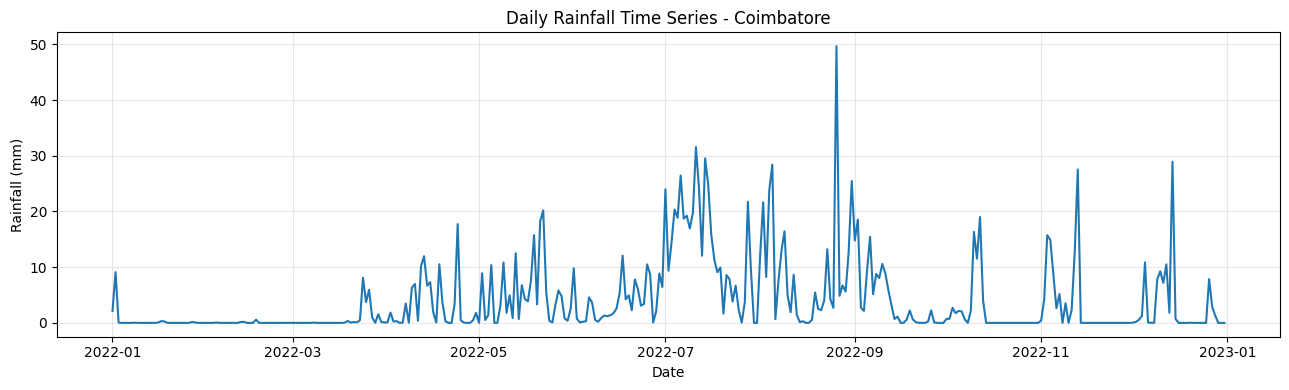


4. LSTM MODEL SUMMARY


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,897 (19.13 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.0240 - val_loss: 0.0089
Epoch 2/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0163 - val_loss: 0.0105
Epoch 3/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0151 - val_loss: 0.0100
Epoch 4/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0142 - val_loss: 0.0096
Epoch 5/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0146 - val_loss: 0.0098
Epoch 6/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0136 - val_loss: 0.0099
Epoch 7/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0137 - val_loss: 0.0100
Epoch 8/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0135 - val_loss: 0.0099
Epoch 9/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0133 - val_loss: 0.0099
Epoch 10/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0144 - val_loss: 0.0099
Epoch 11/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0134 - val_loss: 0.0098

5. TEST SET EVALUATION RESULTS
Selected district: Coimbatore


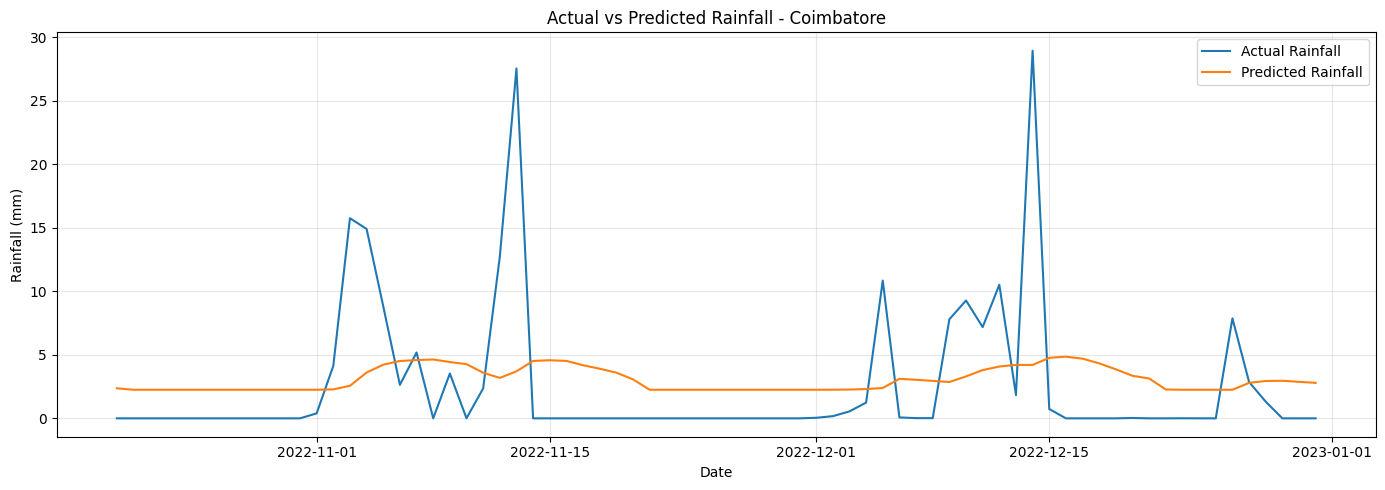

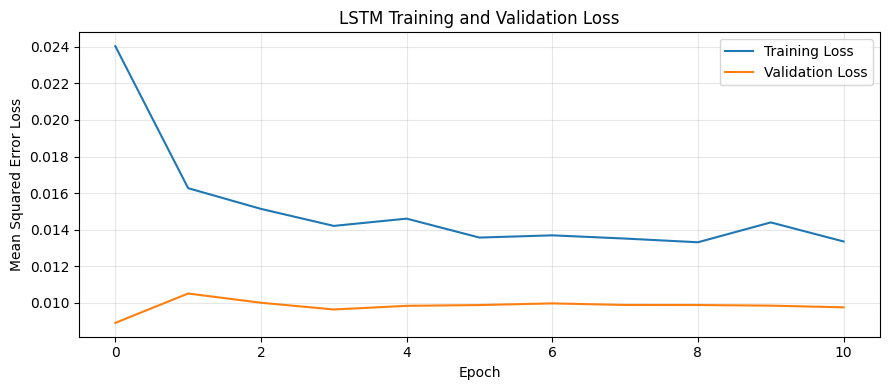


6. FUTURE RAINFALL PREDICTIONS
      Date  Predicted_Rainfall_mm
2023-01-01               2.714181
2023-01-02               2.829103
2023-01-03               2.747458
2023-01-04               2.806921
2023-01-05               2.904740
2023-01-06               3.029629
2023-01-07               3.144904


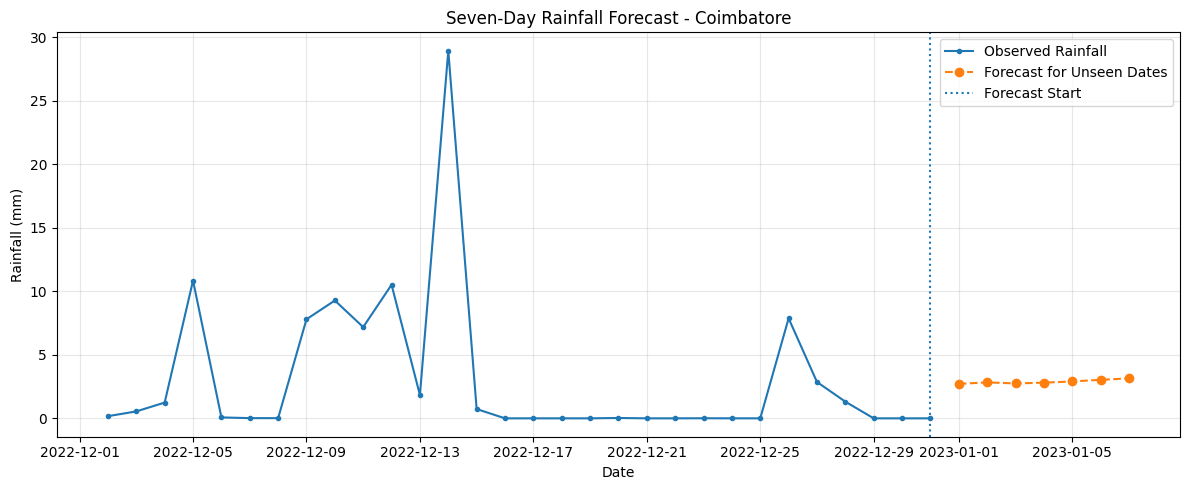


PROJECT COMPLETED SUCCESSFULLY!
Selected district: Coimbatore
MAE: 3.8782 mm
RMSE: 5.6129 mm

All result files are saved in:
/content/rainfall_project_outputs



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:

# ================================================================
# DAILY RAINFALL PREDICTION USING LSTM
# IMD RAINFALL DATASET 2022
# ALL FIVE TASKS - COMPLETE GOOGLE COLAB IMPLEMENTATION
# ================================================================

# TASK 1: IMPORT LIBRARIES AND LOAD THE DATASET

import os
import re
import glob
import shutil
import zipfile
import calendar
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from google.colab import files

warnings.filterwarnings("ignore")
np.random.seed(42)
tf.random.set_seed(42)

print("=" * 65)
print("DAILY RAINFALL PREDICTION USING LSTM")
print("=" * 65)

# Find the previously extracted CSV
csv_path = (
    "/content/imd_rainfall_dataset/"
    "Indian Rainfall Dataset District-wise Daily Measurements.csv"
)

if not os.path.exists(csv_path):
    matches = glob.glob(
        "/content/imd_rainfall_dataset/**/*.csv",
        recursive=True
    )
    if not matches:
        raise FileNotFoundError(
            "Dataset not found. Run the ZIP upload cell first."
        )
    csv_path = matches[0]

# IMPORTANT: Your dataset uses semicolon separators
df = pd.read_csv(csv_path, sep=";", quotechar='"', engine="python")

# Clean column names
df.columns = [
    str(c).strip().strip('"').strip("'")
    for c in df.columns
]

# Remove accidental spaces and quotes from text fields
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype(str).str.strip().str.strip('"')

print("\n1. DATASET LOADED SUCCESSFULLY")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nFirst five rows:")
print(df.head().to_string(index=False))

# Check required columns
if "district" not in [c.lower() for c in df.columns]:
    raise ValueError(
        "District column not found. Check the displayed column names."
    )

# Normalize column-name capitalization for matching
column_lookup = {c.lower(): c for c in df.columns}
district_col = column_lookup["district"]
state_col = column_lookup.get("state")
month_col = column_lookup.get("month")

if month_col is None:
    raise ValueError("Month column not found in the dataset.")

# ================================================================
# TASK 1: SELECT ONE DISTRICT AND CLEAN RAINFALL MEASUREMENTS
# ================================================================

available_districts = sorted(
    df[district_col].dropna().astype(str).unique()
)

# Prefer Coimbatore, then another Tamil Nadu district
matches = [
    d for d in available_districts
    if d.strip().lower() == "coimbatore"
]

if matches:
    selected_district = matches[0]
else:
    tn_districts = []

    if state_col is not None:
        tn_rows = df[
            df[state_col].astype(str).str.strip().str.lower()
            .isin(["tamil nadu", "tamilnadu"])
        ]
        tn_districts = sorted(
            tn_rows[district_col].dropna().astype(str).unique()
        )

    selected_district = (
        tn_districts[0] if tn_districts else available_districts[0]
    )

    print(
        "\nCoimbatore was not found. Using available district:",
        selected_district
    )

district_df = df[
    df[district_col].astype(str).str.strip().str.lower()
    == selected_district.strip().lower()
].copy()

print("\nSelected district:", selected_district)

# Find columns such as 1st, 2nd, 3rd, 4th ... 31st
day_columns = {}

for col in district_df.columns:
    match = re.fullmatch(
        r"(\d{1,2})(?:st|nd|rd|th)?",
        str(col).strip().lower()
    )

    if match:
        day_number = int(match.group(1))
        if 1 <= day_number <= 31:
            day_columns[day_number] = col

if not day_columns:
    raise ValueError(
        "Daily measurement columns were not detected. "
        "Check the printed column names."
    )

# Convert the monthly wide table to a daily time series
records = []

for _, row in district_df.iterrows():

    month_value = str(row[month_col]).strip()

    # Handle numeric month values and month names
    try:
        month_number = int(float(month_value))
    except ValueError:
        month_number = next(
            (
                i for i in range(1, 13)
                if month_value.lower() in [
                    calendar.month_name[i].lower(),
                    calendar.month_abbr[i].lower()
                ]
            ),
            None
        )

    if month_number is None or not 1 <= month_number <= 12:
        continue

    for day_number, col in day_columns.items():

        try:
            date = pd.Timestamp(
                year=2022,
                month=month_number,
                day=day_number
            )
        except ValueError:
            # Skip invalid dates such as February 30
            continue

        value = pd.to_numeric(row[col], errors="coerce")

        # Negative measurements are treated as missing
        if pd.isna(value) or value < 0:
            value = np.nan

        records.append({
            "Date": date,
            "Rainfall": value
        })

daily = pd.DataFrame(records)

if daily.empty:
    raise ValueError(
        "No daily observations were produced for the selected district."
    )

# Combine duplicate observations for the same date
daily = daily.groupby("Date", as_index=False)["Rainfall"].mean()
daily = daily.sort_values("Date").set_index("Date")

# Ensure all dates between the first and last observations exist
all_dates = pd.date_range(
    daily.index.min(),
    daily.index.max(),
    freq="D"
)

daily = daily.reindex(all_dates)
daily.index.name = "Date"

missing_before = daily["Rainfall"].isna().sum()

# Interpolate missing values in chronological order
daily["Rainfall"] = daily["Rainfall"].interpolate(
    method="time",
    limit_direction="both"
)

if daily["Rainfall"].isna().all():
    raise ValueError("All rainfall measurements are missing.")

# Fill any remaining missing observations
daily["Rainfall"] = daily["Rainfall"].fillna(
    daily["Rainfall"].median()
)

# Rainfall cannot be negative
daily["Rainfall"] = daily["Rainfall"].clip(lower=0)

print("\n2. DATA CLEANING COMPLETED")
print("District:", selected_district)
print("Daily records:", len(daily))
print("Missing values before filling:", missing_before)
print("Missing values after filling:",
      daily["Rainfall"].isna().sum())

print("\nCleaned daily rainfall:")
print(daily.head(10))

# Save cleaned data
daily.to_csv("cleaned_rainfall.csv")


# ================================================================
# TASK 2: NORMALIZE DATA AND GENERATE 7-DAY SEQUENCES
# ================================================================

rainfall = daily["Rainfall"].values.reshape(-1, 1)

# Chronological 80% training / 20% testing division
split_index = int(len(rainfall) * 0.80)

if split_index <= 7 or split_index >= len(rainfall):
    raise ValueError("Insufficient data for the selected train/test split.")

# Fit the scaler only on the training period
scaler = MinMaxScaler()
scaler.fit(rainfall[:split_index])

rain_scaled = scaler.transform(rainfall)

X = []
y = []
target_indices = []

# Previous 7 days -> next day's rainfall
for i in range(7, len(rain_scaled)):
    X.append(rain_scaled[i-7:i])
    y.append(rain_scaled[i])
    target_indices.append(i)

X = np.asarray(X, dtype=np.float32)
y = np.asarray(y, dtype=np.float32)
target_indices = np.asarray(target_indices)

# Split based on target dates, not random shuffling
train_mask = target_indices < split_index
test_mask = target_indices >= split_index

X_train = X[train_mask]
y_train = y[train_mask]

X_test = X[test_mask]
y_test = y[test_mask]

if len(X_train) == 0 or len(X_test) == 0:
    raise ValueError("Training or testing sequences are empty.")

print("\n3. SEQUENCE GENERATION COMPLETED")
print("Input sequence length: 7 days")
print("Output: next day's rainfall")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# Plot the daily rainfall time series
plt.figure(figsize=(13, 4))
plt.plot(daily.index, daily["Rainfall"])
plt.title(f"Daily Rainfall Time Series - {selected_district}")
plt.xlabel("Date")
plt.ylabel("Rainfall (mm)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("daily_rainfall_timeseries.png", dpi=150)
plt.show()


# ================================================================
# TASK 3: BUILD THE SEQUENTIAL LEARNING MODEL
# ================================================================

# LSTM learns patterns in ordered sequences of rainfall observations.

model = Sequential([
    tf.keras.Input(shape=(7, 1)),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mean_squared_error"
)

print("\n4. LSTM MODEL SUMMARY")
model.summary()


# ================================================================
# TASK 4: TRAIN USING CHRONOLOGICAL DATA AND EVALUATE
# ================================================================

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

# Predict the testing period
pred_scaled = model.predict(X_test, verbose=0)

# Convert values back to rainfall measurements in millimetres
actual_mm = scaler.inverse_transform(y_test).flatten()
predicted_mm = scaler.inverse_transform(pred_scaled).flatten()

# Prevent negative rainfall predictions
predicted_mm = np.maximum(predicted_mm, 0)

# Calculate MAE and RMSE
mae = mean_absolute_error(actual_mm, predicted_mm)
rmse = np.sqrt(mean_squared_error(actual_mm, predicted_mm))

print("\n" + "=" * 50)
print("5. TEST SET EVALUATION RESULTS")
print("=" * 50)
print("Selected district:", selected_district)
print(f"Mean Absolute Error (MAE): {mae:.4f} mm")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f} mm")
print("=" * 50)

# Save evaluation metrics
with open("evaluation_metrics.txt", "w") as f:
    f.write(f"District: {selected_district}\n")
    f.write(f"MAE: {mae:.4f} mm\n")
    f.write(f"RMSE: {rmse:.4f} mm\n")

test_dates = daily.index[target_indices[test_mask]]

results = pd.DataFrame({
    "Date": test_dates,
    "Actual_Rainfall_mm": actual_mm,
    "Predicted_Rainfall_mm": predicted_mm
})

results.to_csv("test_predictions.csv", index=False)

print("\nSample actual and predicted results:")
print(results.head(10).to_string(index=False))


# ================================================================
# TASK 5A: PLOT ACTUAL VS PREDICTED RAINFALL
# ================================================================

plt.figure(figsize=(14, 5))

plt.plot(
    test_dates,
    actual_mm,
    label="Actual Rainfall",
    linewidth=1.5
)

plt.plot(
    test_dates,
    predicted_mm,
    label="Predicted Rainfall",
    linewidth=1.5
)

plt.title(f"Actual vs Predicted Rainfall - {selected_district}")
plt.xlabel("Date")
plt.ylabel("Rainfall (mm)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("actual_vs_predicted.png", dpi=150)
plt.show()


# Plot training and validation loss
plt.figure(figsize=(9, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("training_loss.png", dpi=150)
plt.show()


# ================================================================
# TASK 5B: PREDICT SEVEN FUTURE, UNSEEN DATES
# ================================================================

future_days = 7

# Start with the last 7 observed daily measurements
last_sequence = rain_scaled[-7:].copy()
future_scaled = []

# Recursive forecasting: each prediction feeds the next prediction
for _ in range(future_days):

    next_value = model.predict(
        last_sequence.reshape(1, 7, 1),
        verbose=0
    )[0, 0]

    future_scaled.append(next_value)

    # Move the 7-day window forward
    last_sequence = np.vstack([
        last_sequence[1:],
        [[next_value]]
    ])

future_mm = scaler.inverse_transform(
    np.array(future_scaled).reshape(-1, 1)
).flatten()

future_mm = np.maximum(future_mm, 0)

future_dates = pd.date_range(
    start=daily.index[-1] + pd.Timedelta(days=1),
    periods=future_days,
    freq="D"
)

future_results = pd.DataFrame({
    "Date": future_dates,
    "Predicted_Rainfall_mm": future_mm
})

print("\n6. FUTURE RAINFALL PREDICTIONS")
print(future_results.to_string(index=False))

future_results.to_csv(
    "future_rainfall_predictions.csv",
    index=False
)

# Plot recent observations and future forecasts
plt.figure(figsize=(12, 5))

plt.plot(
    daily.index[-30:],
    daily["Rainfall"].tail(30),
    label="Observed Rainfall",
    marker="."
)

plt.plot(
    future_dates,
    future_mm,
    label="Forecast for Unseen Dates",
    marker="o",
    linestyle="--"
)

plt.axvline(
    daily.index[-1],
    linestyle=":",
    label="Forecast Start"
)

plt.title(f"Seven-Day Rainfall Forecast - {selected_district}")
plt.xlabel("Date")
plt.ylabel("Rainfall (mm)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("future_forecast.png", dpi=150)
plt.show()


# ================================================================
# SAVE MODEL AND ALL PROJECT OUTPUTS
# ================================================================

model.save("rainfall_lstm_model.keras")

# Organize the results into a single downloadable ZIP
output_folder = "/content/rainfall_project_outputs"
os.makedirs(output_folder, exist_ok=True)

output_files = [
    "cleaned_rainfall.csv",
    "daily_rainfall_timeseries.png",
    "actual_vs_predicted.png",
    "training_loss.png",
    "future_forecast.png",
    "test_predictions.csv",
    "future_rainfall_predictions.csv",
    "evaluation_metrics.txt",
    "rainfall_lstm_model.keras"
]

for filename in output_files:
    if os.path.exists(filename):
        shutil.copy2(
            filename,
            os.path.join(output_folder, filename)
        )

zip_output = shutil.make_archive(
    "/content/rainfall_project_outputs",
    "zip",
    output_folder
)

print("\n" + "=" * 65)
print("PROJECT COMPLETED SUCCESSFULLY!")
print("=" * 65)
print("Selected district:", selected_district)
print(f"MAE: {mae:.4f} mm")
print(f"RMSE: {rmse:.4f} mm")
print("\nAll result files are saved in:")
print(output_folder)

print("\nDownloading the complete results ZIP...")
files.download(zip_output)
